# Analyse de la variabilité

On étudie les résultats du placement bancaire et on explique ceux des labs 1 et 2.
Le montant attendu après 50 ans et les frais de retrait est **0,0199921658… €**.

Ce notebook **lit uniquement les CSV**. Les expériences causales ont été exécutées
séparément avec `run_experiments.py`, qui conserve leurs résultats dans `data/`.

In [1]:
from pathlib import Path
from decimal import Decimal, getcontext
from math import factorial
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Retrouver les données depuis le dossier du notebook ou la racine du dépôt.
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "lab3/analysis/data").exists())
data = root / "lab3/analysis/data"
getcontext().prec = 220  # Ne pas perdre les petites différences lors de l'analyse.

results = pd.read_csv(data / "observed.csv", dtype=str, keep_default_na=False)
references = pd.read_csv(data / "references.csv", dtype=str)
expected = Decimal(references.loc[references.years == "50", "after_fee"].iloc[0])
print("Référence :", str(expected)[:35], "€")
print(len(results), "mesures,", results.config_id.nunique(), "configurations")

Référence : 0.019992165836667903219891152066054 €
30 mesures, 6 configurations


## 1. Quels facteurs changent le résultat ?

`observed.csv` est une copie du CSV local de résultats. Il contient **six configurations**,
répétées cinq fois, sur une seule machine. Les réponses sont converties en `Decimal`
pour comparer leurs valeurs sans perdre les derniers chiffres.

In [2]:
results["value"] = results.answer.map(Decimal)
results["error"] = results.value.map(lambda value: abs(value - expected))
summary = results.groupby(["Language", "JavaVersion", "Implementation"]).agg(
    repetitions=("run", "size"), distinct_answers=("value", "nunique"),
    answer=("value", "first"), error=("error", "first"))
summary["error"] = summary.error.map(lambda value: f"{value:.2E}")
display(summary)

repetitions  distinct_answers  \
Language JavaVersion Implementation                                  
Java     Java 17     BigDecimal                5                 1   
                     Math_E                    5                 1   
         Java 21     BigDecimal                5                 1   
                     Math_E                    5                 1   
Python               Decimal_exp               5                 1   
                     math_exp                  5                 1   

                                                                                answer  \
Language JavaVersion Implementation                                                      
Java     Java 17     BigDecimal      0.01999216583666790321989115206605476936465584...   
                     Math_E                                    -4.3968039301820685E+48   
         Java 21     BigDecimal      0.01999216583666790321989115206605476936465584...   
                     Math_E                                    -4.3968039301820685E+48   
Python               Decimal_exp     0.01999216583666790321989115206605476936465584...   
                     math_exp                                  -4.3968039301820685E+48   

                                        error  
Language JavaVersion Implementation            
Java     Java 17     BigDecimal      1.30E-35  
                     Math_E          4.40E+48  
         Java 21     BigDecimal      1.30E-35  
                     Math_E          4.40E+48  
Python               Decimal_exp     1.30E-35  
                     math_exp        4.40E+48

- **Implémentation :** `Math_E` et `math_exp` donnent environ **−4,40 × 10⁴⁸ €**.
  `BigDecimal` et `Decimal_exp`, à 100 chiffres, donnent **0,019992… €**, avec une erreur
  d'environ **1,3 × 10⁻³⁵ €**.
- **Langage et version :** Python et Java peuvent tous deux donner un bon ou un mauvais
  résultat. Java 17 et 21 donnent les mêmes réponses dans ce CSV.
- **Répétitions :** les cinq essais sont identiques. Un résultat peut donc être
  **répétable et faux**.
- **Autres facteurs :** la précision, la durée et la machine ne varient pas dans ce CSV.
  PyPy et les versions explicites Python 3.10–3.12 ne sont pas représentés ; le Python
  local enregistré est 3.14.4. On ne peut pas mesurer leurs effets ici.

## 2. Un arbre de décision simple

On classe les résultats comme précis si leur erreur est inférieure à **10⁻¹⁰ €**.
La représentation est déduite de l'implémentation du code, pas de la réponse.
On garde une seule ligne par configuration pour ne pas compter les répétitions comme
plusieurs observations indépendantes. L'arbre décrit les six configurations :
**ce n'est ni une preuve causale ni une validation sur d'autres environnements**.

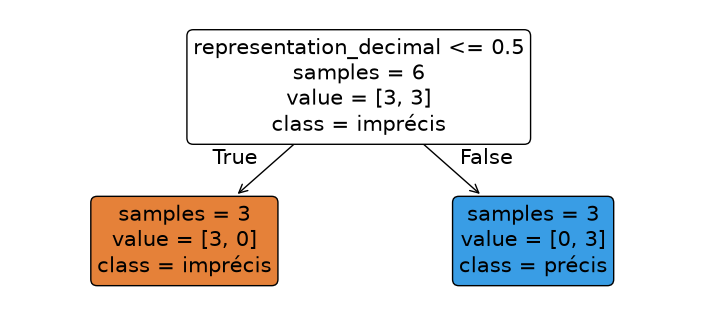

In [3]:
configs = results.drop_duplicates("config_id").copy()
configs["representation"] = configs.Implementation.map({
    "Math_E": "binary64", "math_exp": "binary64",
    "BigDecimal": "decimal", "Decimal_exp": "decimal"})
X = pd.get_dummies(configs[["Language", "JavaVersion", "representation"]])
y = configs.error.map(lambda error: int(error < Decimal("1e-10")))
tree = DecisionTreeClassifier(max_depth=2, random_state=0)
tree.fit(X, y)

plt.figure(figsize=(9, 4))
plot_tree(tree, feature_names=list(X.columns), class_names=["imprécis", "précis"],
          filled=True, impurity=False, rounded=True)
plt.show()

L'arbre sépare les calculs décimaux des calculs en binaire64. Mais ces choix sont liés
aux implémentations : pour expliquer la cause, il faut intervenir sur les facteurs.

## 3. Expériences causales réalisées

Le script séparé a exécuté les mêmes templates en faisant varier la précision,
puis a comparé la récurrence et une série stable à précision égale. Machine,
durée de 50 ans et frais de retrait restent fixés. Le CSV conserve aussi les versions réelles.
Le graphique suivant montre les essais CPython ; des essais Java 17/21 sont également présents.

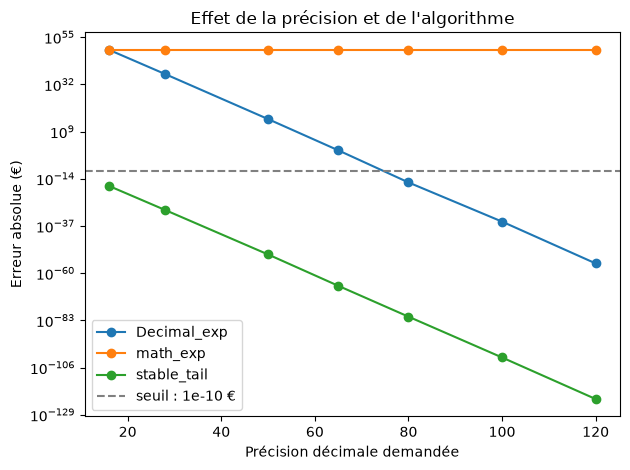

In [4]:
banking = pd.read_csv(data / "causal_banking.csv", dtype=str)
banking["precision"] = banking.precision.astype(int)
banking["value"] = banking.answer.map(Decimal)

sweep = banking[(banking.runtime_id == "CPython") &
                banking.experiment.isin(["precision", "algorithm"])].copy()
sweep = sweep.drop_duplicates(["implementation", "precision"])
sweep["error"] = sweep.value.map(lambda value: float(abs(value - expected)))
for name, group in sweep.groupby("implementation"):
    group = group.sort_values("precision")
    plt.semilogy(group.precision, group.error, "o-", label=name)
plt.axhline(1e-10, color="gray", linestyle="--", label="seuil : 1e-10 €")
plt.xlabel("Précision décimale demandée")
plt.ylabel("Erreur absolue (€)")
plt.title("Effet de la précision et de l'algorithme")
plt.legend()
plt.tight_layout()
plt.show()

**Résultats :** augmenter la précision améliore la récurrence décimale : 65 chiffres
restent insuffisants, 80 donnent une erreur d'environ 10⁻¹⁶ €, et 100 environ 10⁻³⁵ €.
Changer le paramètre de précision ne change rien pour `float`, car cette branche l'ignore.
La série stable atteint déjà le seuil demandé avec 28 chiffres.

**Pourquoi ?** La récurrence est $B_n=n(B_{n-1}-1)$, avec $B_0=e$.
Si la valeur initiale change de $\delta$, la différence finale est $n!\delta$.
À 50 ans, $50!\approx 3,04\times10^{64}$ : une petite erreur initiale peut devenir énorme.
Pour tester ce mécanisme, le script a perturbé e de ±10⁻⁸⁰ et ±10⁻⁴⁰,
en gardant les calculs à 180 chiffres. On compare les mesures à la prédiction :

In [5]:
perturb = banking[banking.experiment == "initial_delta"].copy()
perturb["years"] = perturb.years.astype(int)
base = perturb[perturb.initial_delta == "0"].set_index("years").value
perturb = perturb[perturb.initial_delta != "0"].copy()
perturb["measured"] = perturb.apply(lambda r: r.value - base[r.years], axis=1)
perturb["predicted"] = perturb.apply(
    lambda r: Decimal(r.initial_delta) * factorial(r.years), axis=1)
perturb["relative_error"] = perturb.apply(
    lambda r: abs((r.measured - r.predicted) / r.predicted), axis=1)
display(perturb[["years", "initial_delta", "measured", "predicted"]])
print("Écart relatif maximal :", f"{max(perturb.relative_error):.2E}")

,years,initial_delta,measured,predicted
134,10,1e-80,3.62880000000000000000000000000000000000000000...,3.628800E-74
135,10,-1e-80,-3.6288000000000000000000000000000000000000000...,-3.628800E-74
136,10,1e-40,3.62880000000000000000000000000000000000000000...,3.628800E-34
137,10,-1e-40,-3.6288000000000000000000000000000000000000000...,-3.628800E-34
139,30,1e-80,2.65252859812191058636308480000000000000000000...,2.65252859812191058636308480000000E-48
140,30,-1e-80,-2.6525285981219105863630848000000000000000000...,-2.65252859812191058636308480000000E-48
141,30,1e-40,2.65252859812191058636308480000000000000000000...,2.65252859812191058636308480000000E-8
142,30,-1e-40,-2.6525285981219105863630848000000000000000000...,-2.65252859812191058636308480000000E-8
144,50,1e-80,3.04140932017133780436126081660647688443776415...,3.04140932017133780436126081660647688443776415...
145,50,-1e-80,-3.0414093201713378043612608166064768844377641...,-3.0414093201713378043612608166064768844377641...


Écart relatif maximal : 7.05E-181


Les mesures confirment l'amplification par **n!** avec un écart relatif inférieur à 10⁻⁹⁰.
C'est un mécanisme causal dérivé puis testé, pas seulement une corrélation.

Deux autres contrôles du CSV complètent l'explication :
- Partir de la valeur binaire64 de `math.e`, puis calculer à 180 chiffres, donne déjà
  une erreur énorme : la valeur initiale est une cause, même sans les arrondis de la boucle.
- Java 17 et 21 donnent les mêmes valeurs à source et précision fixées dans les essais.
  Cela ne garantit pas l'égalité pour toutes les JVM ou machines.

Changer uniquement les frais finaux de 0 à 1 € fait passer **1,019992… à 0,019992… €**.
Il faut donc préciser la convention et compter ces frais une seule fois.

## 4. Expliquer les labs 1 et 2

**Associativité.** Le CSV bancaire ne contient pas ces mesures. On lit donc le CSV des
expériences séparées : trois graines et deux tailles d'échantillon par mode.
Pour `float_unit` et `decimal_unit_exact`, les mêmes valeurs de [0,1) sont utilisées ;
la conversion en Decimal est exacte et les additions ont assez de chiffres.

In [6]:
assoc = pd.read_csv(data / "causal_associativity.csv")
display(assoc.groupby("mode").percent.agg(["min", "mean", "max"]).round(3))

# Deux contrôles causaux déjà exécutés : lire leurs réponses sans les relancer.
display(banking[banking.experiment.isin(["rounded_initial", "withdrawal_fee"])][
    ["experiment", "initial_delta", "withdrawal_fee", "answer"]])

,min,mean,max
mode,,,
decimal_unit_exact,100.00,100.000,100.00
float_cancellation,0.00,0.000,0.00
float_unit,82.48,82.784,83.43
float_wide,99.78,99.844,99.90
int_exact,100.00,100.000,100.00


,experiment,initial_delta,withdrawal_fee,answer
148,withdrawal_fee,0,0,1.01999216583666790321989115206605478236565852...
149,withdrawal_fee,0,1,0.01999216583666790321989115206605478236565852...
150,rounded_initial,0E-179,1,0.01999216583666790321989115206605478236565852...
151,rounded_initial,-1.4456468917292501365542249977924683457496696...,1,-439680393018206624623786365125761766890447825...


Le lab 1 trouve environ **17 % d'échecs**, le LLM environ **83 % d'égalités** :
ce sont des résultats complémentaires. Les petites différences viennent des tirages.
Sur les mêmes tirages, des additions décimales exactes donnent 100 % : l'arrondi des
additions cause les échecs. Le domaine compte aussi : ici, les grands exposants donnent
près de 100 %, et l'annulation avec x = 10¹⁶, y = −x donne 0 %.
Le test d'annulation du LLM utilisait un x variable : son résultat d'environ 50 %
ne correspond donc pas à la même distribution.

**Banking :**

| Version | Explication |
|---|---|
| Lab 1, ancienne version avec `math.e` | L'approximation initiale et les arrondis sont amplifiés : résultat énorme mais répétable. |
| Lab 1, version actuelle avec Decimal à 100 chiffres | La précision suffit pour 50 ans : on retrouve 0,019992… € après retrait. |
| Lab 2, calcul naïf du LLM | Même problème d'amplification avec `float` ou `double`. |
| Lab 2, calcul stable du LLM | La série donne déjà le montant après retrait. Le LLM soustrait encore 1 €, d'où sa réponse incorrecte −0,980007… €. |

## 5. Conclusions et recommandations

- **Banking :** préférer la série stable avec Decimal à 50 chiffres. Si l'on garde la
  récurrence, utiliser 100 chiffres et calculer e à cette précision, sans convertir `math.e`.
  La réponse attendue est **0,019992… €**, soit **0,02 € au centime**, après retrait.
- **Associativité :** fixer le type, la distribution, la graine et le nombre de triplets
  pour reproduire un pourcentage. Pour des additions exactes, utiliser des entiers ou
  une représentation exacte adaptée. Augmenter l'échantillon stabilise l'estimation,
  mais ne rend pas l'addition flottante associative.
- **Causalité :** les interventions expliquent les effets de la précision, de l'algorithme,
  de l'erreur initiale, des arrondis et des frais. L'arbre seul ne les prouve pas.
- **Limite :** aucune mesure ARM n'est disponible. Le workflow poussé a été bloqué par
  un problème de facturation GitHub. Il faut le relancer avant de conclure sur les
  architectures, en comparant les mêmes configurations et versions de runtime.

Avant chaque commit : **Restart Kernel and Run All Cells**, puis enregistrer.
Les commandes d'installation, d'ouverture et de reproduction des mesures sont dans le README.